# Fig. 5 — Rouse polymer with surface attraction between two loci

> Type set for PNAS (`pnas-new`): 8 pt text, 7 pt tick labels, 10 pt panel letters as printed. Writes `fig5/fig5.pdf`. The previous layout is kept in `../alt/fig5/`.

Draws the figure from `processed_data/` and saves `fig5/fig5.pdf`.
See `figure_production/README.md` to regenerate the data.

In [1]:
import os

# Reads processed_data/... and art_*.svg relative to figure_production/. Find
# that directory rather than assume the kernel started in it.
DIR_OVERRIDE = None     # set to figure_production's path to skip the search

_SKIP = {"node_modules", "__pycache__", "venv", ".venv", "env", "build", "dist"}


def _ok(d):
    return (os.path.isfile(os.path.join(d, "README.md"))
            and os.path.isdir(os.path.join(d, "processed_data")))


def resolve_figdir():
    if DIR_OVERRIDE:
        if not _ok(DIR_OVERRIDE):
            raise RuntimeError("DIR_OVERRIDE is not figure_production/: " + DIR_OVERRIDE)
        return DIR_OVERRIDE
    starts = []
    nb = globals().get("__vsc_ipynb_file__") or globals().get("__file__")
    if nb:
        starts.append(os.path.dirname(os.path.abspath(nb)))
    starts.append(os.path.abspath(os.getcwd()))
    for start in starts:                      # at or above
        d = start
        for _ in range(6):
            if _ok(d):
                return d
            parent = os.path.dirname(d)
            if parent == d:
                break
            d = parent
    level = [os.path.abspath(os.getcwd())]    # or below, shallowest first
    for _ in range(4):
        nxt = []
        for d in level:
            try:
                names = sorted(os.listdir(d))
            except OSError:
                continue
            for name in names:
                if name.startswith(".") or name in _SKIP:
                    continue
                cand = os.path.join(d, name)
                if not os.path.isdir(cand) or os.path.islink(cand):
                    continue
                if _ok(cand):
                    return cand
                nxt.append(cand)
        level = nxt
    raise RuntimeError(
        "figure_production/ not found from %s -- expected a directory holding "
        "README.md and processed_data/. Set DIR_OVERRIDE above and re-run."
        % os.getcwd())


os.chdir(resolve_figdir())
print("working directory:", os.getcwd())

working directory: /Users/tmora/NextCloudCNRS/Code/droplet/prewet-gene/figure_production


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch


def use_latex():
    plt.rcParams.update({"text.usetex": True, "font.family": "serif",
                         "text.latex.preamble": r"\usepackage{amsmath}"})
    try:
        f = plt.figure()
        f.text(0.5, 0.5, r"$\dfrac{U_{\rm tot}}{k_BT}$ $d^{\rm x}$")
        f.canvas.draw()
        plt.close(f)
        return True
    except Exception as exc:
        plt.close("all")
        # Computer Modern via matplotlib's bundled cmr10, so text widths match
        # the LaTeX render closely (layout checks only)
        plt.rcParams.update({"text.usetex": False, "font.family": "serif",
                             "font.serif": ["cmr10"], "mathtext.fontset": "cm",
                             "axes.formatter.use_mathtext": True})
        print("LaTeX unavailable, falling back to mathtext:",
              type(exc).__name__, str(exc).strip()[:120])
        return False


USETEX = use_latex()
print("usetex:", USETEX)

usetex: True


In [3]:
DATA = "processed_data"
S = json.load(open(os.path.join(DATA, "fig5_scalars.json")))
P = pd.read_csv(os.path.join(DATA, "fig5_potentials.csv"), float_precision="round_trip")
HIST_PATH = os.path.join(DATA, "fig5_hist.csv")
HIST = (pd.read_csv(HIST_PATH, float_precision="round_trip")
        if os.path.exists(HIST_PATH) and S["rouse"] is not None else None)
if HIST is None:
    print("No Rouse histograms: panel D will show the theory only. Run\n"
          "  bash figure_production/fig5/run_fig5_rouse.sh\n"
          "  python figure_production/fig5/prepare_fig5_data.py")

R, L = S["R"], S["L"]
K_LOW, K_HIGH, K_UADS = S["K_LOW"], S["K_HIGH"], S["K_UADS"]
X_DX, X_DO = S["d_x"], S["d_o"]      # thresholds d_x (contact), d_o (exit)
x_all = P["d"].to_numpy()
U_LOW, U_HIGH = P["U_tot_k%d" % K_LOW].to_numpy(), P["U_tot_k%d" % K_HIGH].to_numpy()
RIDGE_LOW, RIDGE_HIGH = S["x_ridge"][K_LOW], S["x_ridge"][K_HIGH]


In [4]:
# PNAS (pnas-new, 9pt): \textwidth = 505.69 TeX pt = 504.0 bp, so a figure built
# 481.9 pt wide is printed 1.0459x larger. The geometry is in built points
# and the type is set so that the PRINTED sizes are 8 pt text,
# 7 pt tick labels and 10 pt panel letters.
PNAS_W, BUILT_W = 504.0, 481.9
PRINT = PNAS_W / BUILT_W
PT_CAPTION, PT_TICK, PT_LETTER = 8 / PRINT, 7 / PRINT, 10 / PRINT
LW, LW_AUX, LW_AXES = 0.5, 0.4, 0.5            # strokes, printed pt (as fig2-4)

W = 481.9                                      # \textwidth, points; H follows the right column

# ---- right column: C over D ------------------------------------------
RX0 = 228.0                     # left edge of the right column (panel letters)
YLAB = 24.0                     # room for a two-line rotated y-label
C_X, C_W, C_GAP = RX0 + YLAB, 100.0, 22.0  # gap: room for the labels centred under the right plot's y axis
D_X, D_W, D_GAP = RX0 + 34.0, 92.0, 28.0      # D needs room for log tick labels;
# its right-hand "10" tick label must end inside W
ROW_TITLE, C_H, C_BELOW = 12.0, 64.0, 27.0   # C is taller: exit / re-entry arcs over the barrier
D_TOP, D_H, D_BELOW = 12.0, 60.0, 21.0   # D_BELOW: tick labels + x label, to the page bottom
GAP_ROW, PAD = 5.0, 2.0
H = PAD + ROW_TITLE + C_H + C_BELOW + GAP_ROW + D_TOP + D_H + D_BELOW   # no band below D

y = H - PAD
C_LET = y;  C_Y = y - ROW_TITLE - C_H;  y = C_Y - C_BELOW - GAP_ROW
D_LET = y;  D_Y = y - D_TOP - D_H

# ---- left column: A on top, B at the bottom -----------------------------------
A_LET = H - PAD
A_PLOT = (102.0, H - 100.0, 92.0, 84.0)       # x, y, w, h of A's potential plot; title just under the page top
B_CHAIN_BOTTOM = 14.0                          # the chain's lowest bead, above the page bottom

# ---- artwork: one scale for every cartoon -----------------------------------
# wide for a 170 mm \textwidth, so 0.92 keeps the drawings at their designed size.
K_ART = 0.92
KMM = K_ART * 72.0 / 25.4

# pinned to a figure point (fx, fy), and everything else in the group keeps its
GROUPS = {
    # A: the top of the "Bulk-mediated attraction" title, clear of the letter
    "A":  ((22.9, 155.8), (16.0, A_LET - 2.0)),
    # A's bridged pair, below the first pair, level with the bottom of A's plot
    # (where it was before A's plot moved up)
    "A2": ((22.9, 176.4), (16.0, H - 56.0)),
    # B: the chain alone (no text block), at the bottom of the left column
    "B":  ((24.25, 231.33), (8.0, B_CHAIN_BOTTOM)),
    # C: the sketch inset, top centre of the low-c plot, above the curve (its
    # top-left corner just under the frame top)
    "C":  ((112.03, 154.03), (C_X + 16.0, C_Y + C_H - 2.0)),
}


# The C inset is a sketch of three curves, not a drawing of objects, and at the
# cartoons' scale its 9 pt labels ("Rouse", "Surface attraction") would collide.
# It gets its own, larger scale; the cartoons all share K_ART.
GROUP_SCALE = {"C": 1.45}


def _k(g):
    return KMM * GROUP_SCALE.get(g, 1.0)


def gx(g, mx):
    (cx, _), (fx, _) = GROUPS[g]
    return fx + (mx - cx) * _k(g)


def gy(g, my):
    (_, cy), (_, fy) = GROUPS[g]
    return fy - (my - cy) * _k(g)


ART = {"a_pair": "A", "a_bridge": "A2", "b_chain": "B", "c_inset": "C"}
# B's letter sits above the chain's top bead (canvas mm 212.91), with room to spare
B_LET = gy("B", 212.91) + 16.0


def art_rect(name):
    """Figure rect (x, y, w, h in points) of an art_*.svg, from its viewBox."""
    import xml.etree.ElementTree as ET
    vb = [float(v) for v in ET.parse("fig5/art_%s.svg" % name).getroot().get("viewBox").split()]
    g = ART[name]
    w, h = vb[2] * _k(g), vb[3] * _k(g)
    return gx(g, vb[0]), gy(g, vb[1]) - h, w, h


RC = {
    "font.size": PT_CAPTION, "axes.labelsize": PT_CAPTION,
    "axes.titlesize": PT_CAPTION, "legend.fontsize": PT_CAPTION,
    "xtick.labelsize": PT_TICK, "ytick.labelsize": PT_TICK,
    "lines.linewidth": LW, "axes.linewidth": LW_AXES,
    "xtick.major.width": LW_AXES, "ytick.major.width": LW_AXES,
    "xtick.minor.width": LW_AUX, "ytick.minor.width": LW_AUX,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "xtick.minor.size": 1.5, "ytick.minor.size": 1.5,
    "axes.labelpad": 1.5, "xtick.major.pad": 1.5, "ytick.major.pad": 1.5,
    "axes.spines.top": True, "axes.spines.right": True,
    # transparent axes: the artwork sits under them (the C inset is inside a plot)
    "axes.facecolor": "none",
}

C_LOW, C_HIGH = "#6666b3", "#66b366"            # navy / green at 60 % on white
C_THEORY, C_SIM = "#1f77b4", "#ff7f0e"
C_DX, C_DSTAR, C_DO = "#322eb6", "#7e7e7e", "#bc518c"
T_DX, T_DO = "#8886d5", "#d99bbd"               # light tints of d_x, d_o (marker lines)
ARROW = dict(arrowstyle="-|>", mutation_scale=5, lw=LW, color="black",
             shrinkA=0, shrinkB=0)


def _rect(x, y, w, h):
    return [x / W, y / H, w / W, h / H]


def arrow_axes(ax):
    """Schematic axes: no box, no ticks, arrowheads."""
    for s in ("top", "right", "left", "bottom"):
        ax.spines[s].set_visible(False)
    ax.set_xticks([]); ax.set_yticks([])
    for end in ((0, 1.06), (1.04, 0)):
        ax.add_patch(FancyArrowPatch((0, 0), end, transform=ax.transAxes,
                                     clip_on=False, **dict(ARROW, lw=LW_AXES)))


def ftext(x, y, s, **kw):
    """Text at figure points."""
    return fig5.text(x / W, y / H, s, **kw)


def schematic_xlabel(ax, s, h_pt):
    """x label of a schematic axis, a fixed 11.5 pt below it -- just under the
    2R label. labelpad would depend on the matplotlib version and the backend."""
    ax.set_xlabel(s)
    ax.xaxis.set_label_coords(0.5, -11.5 / h_pt)


def under_axis(ax, x, s):
    """A label just below a schematic x-axis, at data x."""
    return ax.annotate(s, xy=(x, 0), xycoords=("data", "axes fraction"),
                       xytext=(0, -2.5), textcoords="offset points", ha="center", va="top")


print("figure %.1f x %.1f pt = %.3f x %.3f in" % (W, H, W / 72, H / 72))

figure 481.9 x 203.0 pt = 6.693 x 2.819 in


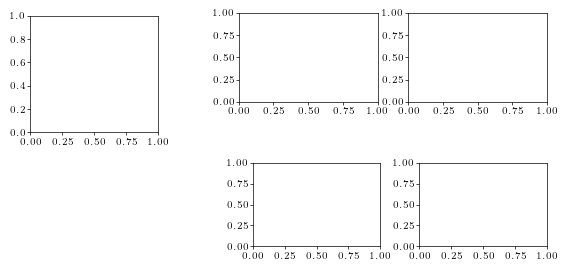

In [5]:
plt.rcParams.update(RC)
fig5 = plt.figure(figsize=(W / 72, H / 72))

aA = fig5.add_axes(_rect(*A_PLOT))
cL = fig5.add_axes(_rect(C_X, C_Y, C_W, C_H))
cR = fig5.add_axes(_rect(C_X + C_W + C_GAP, C_Y, C_W, C_H))
dL = fig5.add_axes(_rect(D_X, D_Y, D_W, D_H))
dR = fig5.add_axes(_rect(D_X + D_W + D_GAP, D_Y, D_W, D_H))

# x-range of the potential plots: from contact (2R, the axis origin) to the box edge L
X_LO, X_HI = R, L

In [6]:
# ---- A: bulk-mediated attraction ------------------------------------------
ftext(gx("A", 36.35), gy("A", 155.8), "Bulk-mediated\nattraction",
      ha="center", va="top", linespacing=1.15)
ftext(gx("A", 36.35), gy("A", 167.7), r"$d$", ha="center", va="baseline")
ftext(gx("A2", 36.35), gy("A2", 188.0), "Capillary bridge", ha="center", va="top")

# the pair potential alone, U_ads(d), at three concentrations: deeper and longer
# ranged as c grows
arrow_axes(aA)
for k in K_UADS:
    aA.plot(x_all, P["U_ads_k%d" % k], color="0.3", lw=LW)
aA.set_xlim(R, 6.0)          # the curves start at contact, on the y axis
aA.set_ylim(-10.0, 1.6)
aA.set_title("Attractive potential", pad=7)
aA.add_patch(FancyArrowPatch((2.6, -3.0), (3.55, -3.0), **dict(ARROW, mutation_scale=6)))
aA.text(3.65, -3.0, r"Increasing $c$", ha="left", va="center")
under_axis(aA, R, r"$2R$")
schematic_xlabel(aA, r"Distance $d$", A_PLOT[3])

In [7]:
# ---- B: the chain (Enhancer ... Anchor + Probe) -------------------------------
ftext(gx("B", 41.0), gy("B", 219.0), "Enhancer", ha="center", va="baseline")
ftext(gx("B", 74.55), gy("B", 219.0), "Anchor + Probe", ha="center", va="baseline")
ftext(gx("B", 57.75), gy("B", 227.4), r"$s$", ha="center", va="top")
ftext(gx("B", 84.6), gy("B", 227.4), r"$a$", ha="center", va="top")


Text(0.3431940171205514, 0.11945293045265903, '$a$')

In [8]:
# ---- C: total potential, low and high concentration -----------------------
# y-limits from the data. Low c: the whole curve. High c: the contact well
# broad minimum keep the same printed scale as at low c.
YLIM_LOW = (-3.42, -1.28)
YLIM_HIGH = (-3.42, -1.90)    # headroom above the barrier for the exit / re-entry arcs
for ax, U, col, ridge, title, ylim in (
        (cL, U_LOW, C_LOW, RIDGE_LOW, "Low concentration", YLIM_LOW),
        (cR, U_HIGH, C_HIGH, RIDGE_HIGH, "High concentration", YLIM_HIGH)):
    arrow_axes(ax)
    ax.plot(x_all, U, color=col, lw=LW)
    ax.axvline(ridge, color=col, lw=LW_AUX, ls=(0, (3, 2)))
    ax.set_xlim(X_LO, X_HI)
    ax.set_ylim(*ylim)
    ax.set_title(title, pad=4)
    if ax is cL:
        under_axis(ax, R, r"$2R$")                 # at the origin, centred on the y axis
    if ax is cR:
        under_axis(ax, ridge, r"$d^*$")            # under the ridge line
    else:
        # at low c the ridge is almost at contact: under the axis "d*" would sit
        # on "2R", so it goes just right of its line, above the axis
        ax.annotate(r"$d^*$", xy=(ridge, 0), xycoords=("data", "axes fraction"),
                    xytext=(2.0, 2.0), textcoords="offset points", ha="left", va="bottom")
    schematic_xlabel(ax, r"Distance $d$", C_H)
cL.set_ylabel("Potential\n" + r"$U_{\rm tot}(d)$", labelpad=3)

# the inset sketch, U_tot = Rouse + surface attraction, top centre of the low-c
# art_c_inset.svg)
ftext(gx("C", 118.56), gy("C", 155.61), r"$=$", ha="center", va="center")
ftext(gx("C", 126.95), gy("C", 155.61), r"$+$", ha="center", va="center")
ftext(gx("C", 122.64), gy("C", 157.4), "Rouse", ha="center", va="top")
# "attraction" is wider than its sketch: right-align it on the plot's right edge
# (lines right-aligned too) so it neither overruns the frame nor runs into "Rouse"
ftext(C_X + C_W - 1.0, gy("C", 157.4), "Surface\nattraction",
      ha="right", va="top", multialignment="right", linespacing=1.0)
# ---- C, high c: exit over the ridge and re-entry, with the two thresholds -------
from matplotlib.path import Path

for xv, col in ((X_DX, T_DX), (X_DO, T_DO)):
    cR.axvline(xv, color=col, lw=LW, ls=(0, (3, 2)), zorder=1)
# "d_x" centred under its line (the y axis: contact is the origin), "= 2R" on
# the line below
under_axis(cR, X_DX, r"$d_{\rm x}$")
cR.annotate(r"$=2R$", xy=(X_DX, 0), xycoords=("data", "axes fraction"),
            xytext=(0, -11.5), textcoords="offset points", ha="center", va="top")
under_axis(cR, X_DO, r"$d_{\rm o}$")


def bezier_arrow(ax, pts):
    """Cubic Bezier arrow through control points in data coordinates, with an
    open arrowhead."""
    ax.add_patch(FancyArrowPatch(path=Path(pts, [Path.MOVETO] + [Path.CURVE4] * 3),
                                 transform=ax.transData, arrowstyle="->,head_length=0.55,head_width=0.3",
                                 mutation_scale=6, lw=LW, color="black", clip_on=False,
                                 shrinkA=0, shrinkB=0, zorder=4))


# exit leaves the contact well just right of d_x, clears the barrier and lands
# above the curve just short of d_o; re-entry starts in the open basin and ends
# on d_x
Y0 = YLIM_HIGH[0]
bezier_arrow(cR, [(X_DX + 0.08, Y0), (X_DX + 0.12, -2.20),
                  (X_DO - 0.28, -2.15), (X_DO - 0.08, -2.75)])
bezier_arrow(cR, [(7.0, -3.10), (6.4, -1.80), (3.4, -1.75), (X_DX + 0.06, -2.25)])
cR.text(3.9, -2.37, "exit", ha="left", va="bottom")     # just right of the ridge line
cR.text(7.15, -2.55, "re-entry", ha="left", va="center")


Text(7.15, -2.55, 're-entry')

In [9]:
_trapz = getattr(np, "trapezoid", None) or np.trapz   # numpy 1.x and 2.x
for ax, U, col_key, ridge in ((dL, U_LOW, "p_low", RIDGE_LOW), (dR, U_HIGH, "p_high", RIDGE_HIGH)):
    p = np.exp(-(U - U.min()))
    p /= _trapz(p, x_all)                        # density on [R, L], as the histogram
    if HIST is not None:
        ax.stairs(HIST[col_key].to_numpy(),
                  np.r_[HIST["x_lo"].to_numpy(), HIST["x_hi"].to_numpy()[-1]],
                  fill=True, color=C_SIM, alpha=0.6, lw=0, label="simulation")
    ax.plot(x_all, p, color=C_THEORY, lw=LW, label=r"$e^{-U_{\rm tot}}/Z$")
    ax.axvline(ridge, color="0.55", lw=LW_AUX, ls=(0, (3, 2)), zorder=3)
    ax.set_yscale("log")
    ax.set_xlim(R, L)
    ax.set_xticks([4, 6, 8, 10])
    ax.set_xlabel(r"Distance $d$")
dL.set_ylabel(r"$P_{\rm eq}(d)$")
dR.legend(loc="upper right", edgecolor="none", framealpha=0, handlelength=1.4,
          borderaxespad=0.2, labelspacing=0.3)
if HIST is None:
    dL.text(0.97, 0.06, "simulation pending:\nrun\\_fig5\\_rouse.sh" if USETEX
            else "simulation pending:\nrun_fig5_rouse.sh", transform=dL.transAxes,
            ha="right", va="bottom", color="red", fontsize=PT_TICK)
# closed and open, either side of the ridge, just above the high-c frame (the
# closed band is too narrow to hold a label inside the plot)
dR.annotate("Closed", xy=(RIDGE_HIGH, 1.0), xycoords=("data", "axes fraction"),
            xytext=(-1.5, 1.5), textcoords="offset points", ha="right", va="bottom")
dR.annotate("Open", xy=(RIDGE_HIGH, 1.0), xycoords=("data", "axes fraction"),
            xytext=(1.5, 1.5), textcoords="offset points", ha="left", va="bottom")
dR.plot([RIDGE_HIGH] * 2, [1.0, 1.0 + 9.0 / D_H], transform=dR.get_xaxis_transform(),
        color="0.55", lw=LW_AUX, ls=(0, (3, 2)), clip_on=False)

In [10]:
# ---- panel letters -------------------------------------------------------------
for x_let, y_let, letter in ((1.0, A_LET, "A"), (1.0, B_LET, "B"),
                             (RX0, C_LET, "C"), (RX0, D_LET, "D")):
    fig5.text(x_let / W, y_let / H, letter, usetex=False, fontfamily="Arial",
              fontsize=PT_LETTER, ha="left", va="top")

Saved figure to fig5/fig5.pdf
artwork:
  a_pair     (inkscape)  71.5 x  35.5 pt at ( 15.3, 147.5)
  a_bridge   (inkscape)  56.2 x  29.2 pt at ( 23.0, 118.5)
  b_chain    (inkscape) 195.2 x  48.8 pt at (  7.2,  13.2)
  c_inset    (inkscape)  83.7 x  11.9 pt at (268.0, 175.1)


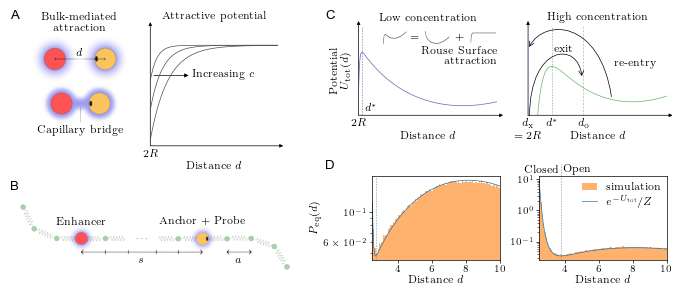

In [11]:
# ---- save, then composite the artwork underneath -------------------------------
OUT_DIR = "fig5"
path = os.path.join("fig5", "fig5.pdf")   # art still read from fig5/
fig5.savefig(path, format="pdf", transparent=True)
# no bbox_inches: that would re-crop the page and lose \textwidth.
# transparent=True: the artwork goes UNDER this layer, and matplotlib's white
# figure patch would otherwise cover it.
print("Saved figure to", path)


def _cairosvg():
    """cairosvg, or None if it cannot actually be used. `pip install cairosvg` on
    macOS leaves it importable but unusable (no cairo C library; cairocffi raises
    OSError, not ImportError), so every use falls back to Inkscape on any failure.
    Homebrew's cairo lives in /opt/homebrew/lib, which python.org Python never
    searches; point ctypes.util.find_library at it before the import."""
    import ctypes.util
    brew = "/opt/homebrew/lib/libcairo.2.dylib"
    if os.path.exists(brew) and not getattr(ctypes.util, "_brew_cairo", False):
        _find = ctypes.util.find_library
        ctypes.util.find_library = lambda name: (
            brew if name in ("cairo-2", "cairo", "libcairo-2") else _find(name))
        ctypes.util._brew_cairo = True
    try:
        import cairosvg
        return cairosvg
    except Exception:
        return None


def _inkscape():
    """Inkscape's CLI; on macOS an app bundle, not on PATH."""
    import shutil
    exe = shutil.which("inkscape")
    if exe:
        return exe
    for cand in ("/Applications/Inkscape.app/Contents/MacOS/inkscape",
                 os.path.expanduser("~/Applications/Inkscape.app/Contents/MacOS/inkscape")):
        if os.path.exists(cand):
            return cand
    return None


def svg_to_pdf(svg_path, pdf_path):
    """SVG -> PDF. The page box is read back by the caller, never assumed."""
    cs = _cairosvg()
    if cs is not None:
        try:
            cs.svg2pdf(url=svg_path, write_to=pdf_path)
            return "cairosvg"
        except Exception:
            pass
    import subprocess
    exe = _inkscape()
    if exe:
        subprocess.run([exe, svg_path, "--export-type=pdf", "--export-area-page",
                        "--export-filename=" + pdf_path], check=True, capture_output=True)
        return "inkscape"
    raise RuntimeError("no working SVG converter: install Inkscape, or cairosvg "
                       "plus the cairo C library (brew install cairo)")


def svg_to_png(svg_path, width_px):
    """SVG -> PNG bytes, for the inline preview only."""
    cs = _cairosvg()
    if cs is not None:
        try:
            return cs.svg2png(url=svg_path, output_width=width_px)
        except Exception:
            pass
    exe = _inkscape()
    if exe is None:
        return None
    import subprocess, tempfile
    tmp = os.path.join(tempfile.mkdtemp(), "preview.png")
    subprocess.run([exe, svg_path, "--export-type=png", "--export-area-page",
                    "--export-width=%d" % width_px, "--export-filename=" + tmp],
                   check=True, capture_output=True)
    data = open(tmp, "rb").read()
    os.remove(tmp)
    return data


def stamp_artwork(page_pdf, names):
    """Lay every art_*.svg down on a blank page, at the rect art_rect() gives it,
    then put the transparent matplotlib layer over the top: type over drawing."""
    from pypdf import PdfReader, PdfWriter, Transformation, PageObject
    import shutil, tempfile
    scratch = tempfile.mkdtemp()               # intermediates never touch the repo
    out = PageObject.create_blank_page(width=W, height=H)
    for name in names:
        tmp = os.path.join(scratch, name + ".pdf")
        how = svg_to_pdf(os.path.join(OUT_DIR, "art_%s.svg" % name), tmp)
        art = PdfReader(tmp).pages[0]
        bw, bh = float(art.mediabox.width), float(art.mediabox.height)
        x, y, w, h = art_rect(name)
        s = w / bw
        assert abs(h / bh - s) < 0.01 * s, "%s: non-uniform scale" % name
        out.merge_transformed_page(art, Transformation().scale(s).translate(x, y))
        print("  %-10s (%s) %5.1f x %5.1f pt at (%5.1f, %5.1f)" % (name, how, w, h, x, y))
    out.merge_page(PdfReader(page_pdf).pages[0])
    wr = PdfWriter(); wr.add_page(out)
    with open(page_pdf, "wb") as fh:
        wr.write(fh)
    shutil.rmtree(scratch, ignore_errors=True)


def _missing_deps():
    import importlib.util as iu
    missing = []
    if iu.find_spec("pypdf") is None:
        missing.append("pypdf")
    if _cairosvg() is None and _inkscape() is None:
        missing.append("cairosvg (or Inkscape)")
    return missing


_missing = _missing_deps()
if _missing:
    print("\nThe artwork was NOT added: missing %s. The figure is saved without it.\n"
          "    pip install pypdf        # always needed\n"
          "    and either Inkscape, or: pip install cairosvg && brew install cairo\n"
          % ", ".join(_missing))
else:
    print("artwork:")
    stamp_artwork(path, list(ART))

# ---- inline preview: a raster copy of the artwork, added after savefig ---------
def preview_artwork(dpi=300):
    import io
    import matplotlib.image as mpimg
    for name in ART:
        x, y, w, h = art_rect(name)
        buf = svg_to_png(os.path.join(OUT_DIR, "art_%s.svg" % name), max(int(w / 72 * dpi), 1))
        if buf is None:
            return False
        ax = fig5.add_axes(_rect(x, y, w, h), zorder=-1)
        ax.imshow(mpimg.imread(io.BytesIO(buf), format="png"), interpolation="bilinear",
                  aspect="auto")
        ax.set_axis_off()
    return True


if not preview_artwork():
    print("(no inline preview of the artwork: neither cairosvg nor Inkscape found)")

from IPython.display import display
display(fig5)